# Visualizing the ANARCI bit score with a real TCR3d sequence

This short notebook explains every part of

\[
S_{\text{ANARCI}}
=
\log_2\left(\frac{P(X\mid M)}{P(X\mid N)}\right)-B
\]

using the **1AO7 TCR alpha chain** from your `TCR3d_ClassI_ClassII_TCR_AB.fasta` file.

We will:

1. run ANARCI on the real sequence;
2. identify the selected TCR profile-HMM;
3. explain every symbol in the equation;
4. calculate a real residue-level HMM emission contribution;
5. visualize the score and bias correction;
6. provide a manual calculation exercise.

> Important: ANARCI's reported value is calculated by HMMER's Forward/Backward algorithms. A complete exact calculation involves many possible match, insertion, and deletion paths. The notebook shows the mathematics and real model components without pretending that the final Forward score is a simple BLOSUM-style sum.


## Step 1 — Install ANARCI and HMMER

A CPU runtime is sufficient. This cell installs the current ANARCI package used by the other notebooks and the `hmmscan` program that actually calculates the score.


In [ ]:
!apt-get -qq update
!apt-get -qq install -y hmmer
%pip install -q "ANARCI==2026.2.13.2" "biopython==1.85" pandas matplotlib


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libdivsufsort3:amd64.
(Reading database ... 118332 files and directories currently installed.)
Preparing to unpack .../libdivsufsort3_2.0.1-5_amd64.deb ...
Unpacking libdivsufsort3:amd64 (2.0.1-5) ...
Selecting previously unselected package hmmer.
Preparing to unpack .../hmmer_3.3.2+dfsg-1_amd64.deb ...
Unpacking hmmer (3.3.2+dfsg-1) ...
Setting up libdivsufsort3:amd64 (2.0.1-5) ...
Setting up hmmer (3.3.2+dfsg-1) ...
Processing triggers for man-db (2.10.2-1) ...
Processing triggers for libc-bin (2.35-0ubuntu3.13) ...
/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic lin

## Step 2 — Use a real sequence from your FASTA bundle

The record below was copied from `TCR3d_ClassI_ClassII_TCR_AB.fasta`:

```text
>1AO7|mhc_class=I|chain=D|expected_chain=A|tcr_type=Alpha|tcr_name=A6
```

`expected_chain=A` means that the TCR3d metadata expects this to be a TCR alpha chain.


In [ ]:
EXAMPLE_ID = "1AO7|mhc_class=I|chain=D|expected_chain=A|tcr_type=Alpha|tcr_name=A6"
EXAMPLE_SEQUENCE = (
    "KEVEQNSGPLSVPEGAIASLNCTYSDRGSQSFFWYRQYSGKSPELIMSIYSNGDKEDGRF"
    "TAQLNKASQYVSLLIRDSQPSDSATYLCAVTTDSWGKLQFGAGTQVVVTPDIQNPDPAVY"
    "QLRDSKSSDKSVCLFTDFDSQTNVSQSKDSDVYITDKTVLDMRSMDFKSNSAVAWSNKSD"
    "FACANAFNNSIIPEDTFFPSPESS"
)

print("Source record:", EXAMPLE_ID)
print("Full PDB-chain sequence length:", len(EXAMPLE_SEQUENCE), "amino acids")
print(EXAMPLE_SEQUENCE)


Source record: 1AO7|mhc_class=I|chain=D|expected_chain=A|tcr_type=Alpha|tcr_name=A6
Full PDB-chain sequence length: 204 amino acids
KEVEQNSGPLSVPEGAIASLNCTYSDRGSQSFFWYRQYSGKSPELIMSIYSNGDKEDGRFTAQLNKASQYVSLLIRDSQPSDSATYLCAVTTDSWGKLQFGAGTQVVVTPDIQNPDPAVYQLRDSKSSDKSVCLFTDFDSQTNVSQSKDSDVYITDKTVLDMRSMDFKSNSAVAWSNKSDFACANAFNNSIIPEDTFFPSPESS


## Step 3 — Let ANARCI select the best alpha/beta profile-HMM

ANARCI sends the sequence to HMMER's `hmmscan`. We permit only alpha (`A`) and beta (`B`) chain models. ANARCI then retains the most significant acceptable domain hit.


In [ ]:
import math
import pandas as pd
from IPython.display import Markdown, display
from anarci import anarci as run_anarci

numbered, details, hit_tables = run_anarci(
    [(EXAMPLE_ID, EXAMPLE_SEQUENCE)],
    scheme="imgt",
    allow={"A", "B"},
    output=False,
    ncpu=1,
)

if not details[0]:
    raise RuntimeError("ANARCI did not find an alpha/beta variable domain")

selected = details[0][0]
MODEL_NAME = f"{selected['species']}_{selected['chain_type']}"
ANARCI_BITSCORE = float(selected["bitscore"])
BIAS_BITS = float(selected.get("bias") or 0.0)
UNCORRECTED_BITS = ANARCI_BITSCORE + BIAS_BITS
EVALUE = float(selected["evalue"])

selected_summary = pd.DataFrame([
    {"Result": "Selected profile-HMM", "Value": MODEL_NAME},
    {"Result": "Predicted chain", "Value": selected["chain_type"]},
    {"Result": "ANARCI/HMMER bit score", "Value": f"{ANARCI_BITSCORE:.3f} bits"},
    {"Result": "Composition-bias correction", "Value": f"{BIAS_BITS:.3f} bits"},
    {"Result": "Score before bias correction", "Value": f"{UNCORRECTED_BITS:.3f} bits"},
    {"Result": "E-value", "Value": f"{EVALUE:.3e}"},
])
display(selected_summary)

hit_df = pd.DataFrame(hit_tables[0][1:], columns=hit_tables[0][0])
tcr_hit_df = hit_df[
    hit_df["id"].str.endswith(("_A", "_B"))
].sort_values("bitscore", ascending=False)
print("Candidate alpha/beta models found by HMMER:")
display(tcr_hit_df)


,Result,Value
0,Selected profile-HMM,human_A
1,Predicted chain,A
2,ANARCI/HMMER bit score,129.900 bits
3,Composition-bias correction,0.100 bits
4,Score before bias correction,130.000 bits
5,E-value,8.100e-41


Candidate alpha/beta models found by HMMER:


,id,description,evalue,bitscore,bias,query_start,query_end
0,human_A,,8.100000e-41,129.9,0.1,1,110
1,mouse_A,,2.500000e-39,125.1,0.1,1,110


## Step 4 — Define every variable

\[
\boxed{
S_{\text{ANARCI}}
=
\log_2\left(\frac{P(X\mid M)}{P(X\mid N)}\right)-B
}
\]

| Variable or symbol | Meaning in this example |
|---|---|
| \(S_{\text{ANARCI}}\) | Final HMMER domain bit score reported by ANARCI |
| \(X\) | The 1AO7 amino-acid sequence/domain being evaluated |
| \(M\) | The selected TCR profile-HMM, found in the previous cell |
| \(N\) | HMMER's null model for an unrelated background protein |
| \(P(X\mid M)\) | Probability of sequence \(X\) under the selected TCR model |
| \(P(X\mid N)\) | Probability of the same sequence under the null model |
| \(\mid\) | “Given” or “assuming” |
| \(P(X\mid M)/P(X\mid N)\) | Likelihood ratio: how much better the TCR model explains the sequence |
| \(\log_2\) | Base-2 logarithm, converting the ratio to bits |
| \(B\) | `null2` composition-bias correction, in bits |

The numerator must be the **TCR-model probability** and the denominator must be the **null-model probability**. Reversing them would reverse the sign of the evidence.


In [ ]:
variable_values = pd.DataFrame([
    {"Symbol": "X", "Value in this run": "1AO7 TCR alpha variable-domain sequence"},
    {"Symbol": "M", "Value in this run": MODEL_NAME},
    {"Symbol": "N", "Value in this run": "HMMER background/null protein model"},
    {"Symbol": "B", "Value in this run": f"{BIAS_BITS:.3f} bits"},
    {"Symbol": "S_ANARCI", "Value in this run": f"{ANARCI_BITSCORE:.3f} bits"},
])
display(variable_values)


,Symbol,Value in this run
0,X,1AO7 TCR alpha variable-domain sequence
1,M,human_A
2,N,HMMER background/null protein model
3,B,0.100 bits
4,S_ANARCI,129.900 bits


## Step 5 — Visualize the bias correction

HMMER first obtains the profile-versus-null log-odds evidence. It then subtracts the `null2` correction:

\[
S_{\text{ANARCI}}
=
S_{\text{before bias}}-B
\]


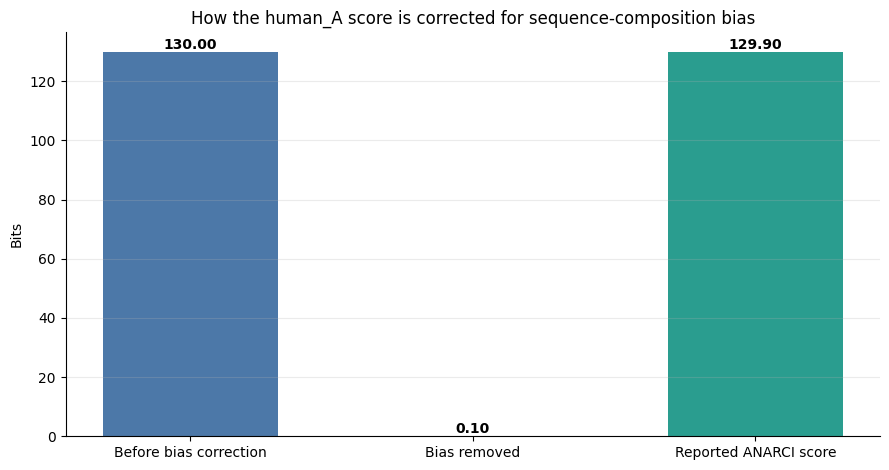

Check: 130.000 - 0.100 = 129.900 bits


In [ ]:
import matplotlib.pyplot as plt

labels = ["Before bias correction", "Bias removed", "Reported ANARCI score"]
values = [UNCORRECTED_BITS, BIAS_BITS, ANARCI_BITSCORE]
colors = ["#4C78A8", "#F2A541", "#2A9D8F"]

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(labels, values, color=colors, width=0.62)
ax.set_ylabel("Bits")
ax.set_title(f"How the {MODEL_NAME} score is corrected for sequence-composition bias")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value, f"{value:.2f}",
            ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

print(
    f"Check: {UNCORRECTED_BITS:.3f} - {BIAS_BITS:.3f} "
    f"= {ANARCI_BITSCORE:.3f} bits"
)


## Step 6 — Inspect a real amino-acid contribution from the selected HMM

ANARCI's HMM file stores probabilities as negative natural logarithms:

\[
c=-\ln(p) \qquad\Longrightarrow\qquad p=e^{-c}
\]

For a residue aligned to match state \(k\), its emission log-odds contribution is:

\[
s_k
=
\log_2\left(\frac{p_{M,k}(x)}{p_N(x)}\right)
=
\frac{c_N(x)-c_{M,k}(x)}{\ln(2)}
\]

Here, \(p_{M,k}(x)\) is the selected HMM's probability of amino acid \(x\) at match state \(k\), and \(p_N(x)\) is the background probability of that amino acid.


In [ ]:
from pathlib import Path
from anarci.anarci import HMM_path


def read_hmmer_ascii_model(hmm_file, model_name):
    # Read match-emission and background costs from one HMMER3 ASCII model.
    lines = Path(hmm_file).read_text().splitlines()
    start = next(i for i, line in enumerate(lines) if line == f"NAME  {model_name}")
    end = next(i for i in range(start, len(lines)) if lines[i].strip() == "//")
    model_lines = lines[start:end]

    hmm_header_index = next(i for i, line in enumerate(model_lines) if line.startswith("HMM "))
    amino_acids = model_lines[hmm_header_index].split()[1:]
    compo_index = next(i for i, line in enumerate(model_lines) if line.strip().startswith("COMPO"))

    # The line after COMPO contains the standard insert/background emission costs.
    background_values = [float(x) for x in model_lines[compo_index + 1].split()[:20]]
    background_cost = dict(zip(amino_acids, background_values))

    match_costs = {}
    for line in model_lines[compo_index + 3:]:
        fields = line.split()
        if fields and fields[0].isdigit():
            position = int(fields[0])
            values = [float(x) for x in fields[1:21]]
            match_costs[position] = dict(zip(amino_acids, values))
    return background_cost, match_costs


hmm_file = Path(HMM_path) / "ALL.hmm"
background_cost, match_costs = read_hmmer_ascii_model(hmm_file, MODEL_NAME)

numbered_domain = numbered[0][0][0]
emission_rows = []
for (position, insertion), amino_acid in numbered_domain:
    position = int(position)
    insertion = str(insertion).strip()
    if amino_acid == "-" or insertion or position not in match_costs:
        continue
    model_cost = match_costs[position][amino_acid]
    null_cost = background_cost[amino_acid]
    p_model = math.exp(-model_cost)
    p_null = math.exp(-null_cost)
    contribution = math.log2(p_model / p_null)
    emission_rows.append({
        "IMGT_position": position,
        "amino_acid": amino_acid,
        "model_cost_-ln(p)": model_cost,
        "null_cost_-ln(p)": null_cost,
        "P_residue_given_model_state": p_model,
        "P_residue_given_null": p_null,
        "emission_contribution_bits": contribution,
    })

emission_df = pd.DataFrame(emission_rows)
display(emission_df.head(10).round({
    "model_cost_-ln(p)": 5,
    "null_cost_-ln(p)": 5,
    "P_residue_given_model_state": 5,
    "P_residue_given_null": 5,
    "emission_contribution_bits": 3,
}))

first = emission_df.iloc[0]
display(Markdown(
    f"For the first occupied IMGT match position, the residue is **{first.amino_acid}**.  "
    f"Its model probability is **{first.P_residue_given_model_state:.5f}**, and its null "
    f"probability is **{first.P_residue_given_null:.5f}**. Therefore,  "
    f"$\\log_2({first.P_residue_given_model_state:.5f}/"
    f"{first.P_residue_given_null:.5f})={first.emission_contribution_bits:+.3f}$ bits."
))


,IMGT_position,amino_acid,model_cost_-ln(p),null_cost_-ln(p),P_residue_given_model_state,P_residue_given_null,emission_contribution_bits
0,2,K,2.32785,2.67741,0.09751,0.06874,0.504
1,3,E,2.15595,2.73123,0.11579,0.06514,0.830
2,4,V,0.87030,2.98518,0.41883,0.05053,3.051
3,5,E,1.76400,2.73123,0.17136,0.06514,1.395
4,6,Q,0.84731,3.18146,0.42857,0.04152,3.367
5,7,N,2.64906,2.90347,0.07072,0.05483,0.367
6,8,S,2.55189,2.37887,0.07793,0.09266,-0.250
7,9,G,2.70367,2.40513,0.06696,0.09025,-0.431
8,10,P,3.12388,2.73739,0.04399,0.06474,-0.558
9,11,L,1.11338,2.69355,0.32845,0.06764,2.280


For the first occupied IMGT match position, the residue is **K**.  Its model probability is **0.09751**, and its null probability is **0.06874**. Therefore,  $\log_2(0.09751/0.06874)=+0.504$ bits.

## Step 7 — Visualize real residue-level evidence

Positive bars mean the amino acid is more likely at that TCR-model position than in a random background protein. Negative bars mean it is less likely.

This chart shows **match-emission contributions only**. It does not include transition scores, insertions, deletions, local alignment boundaries, alternative alignment paths, or the bias correction, so its sum is not expected to equal the final ANARCI score.


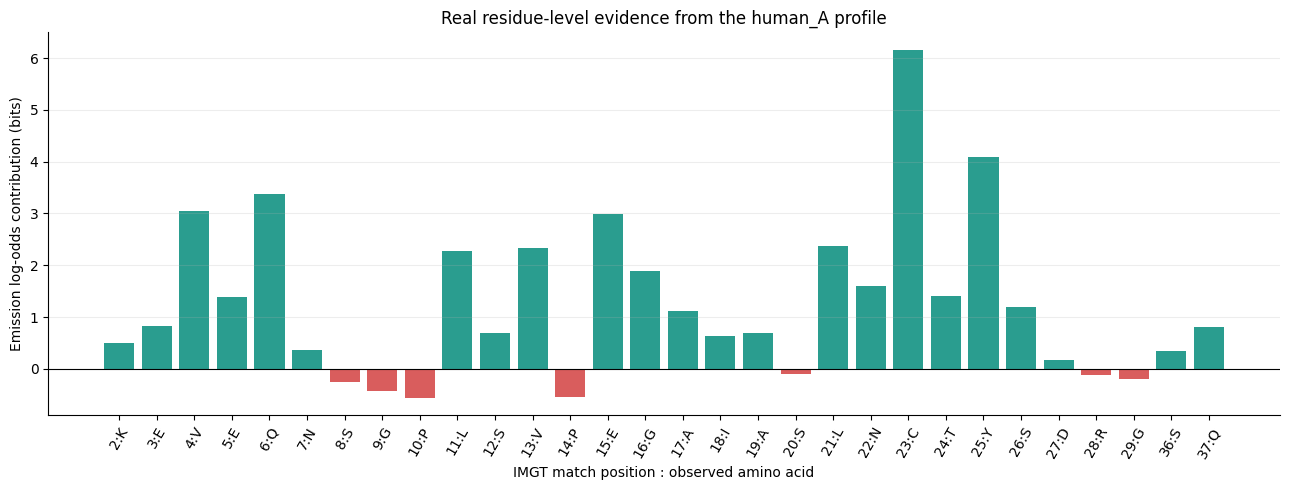

In [ ]:
plot_df = emission_df.head(30).copy()
plot_df["label"] = plot_df["IMGT_position"].astype(str) + ":" + plot_df["amino_acid"]
bar_colors = ["#2A9D8F" if value >= 0 else "#D95D5D"
              for value in plot_df["emission_contribution_bits"]]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(plot_df["label"], plot_df["emission_contribution_bits"], color=bar_colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("IMGT match position : observed amino acid")
ax.set_ylabel("Emission log-odds contribution (bits)")
ax.set_title(f"Real residue-level evidence from the {MODEL_NAME} profile")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


## Step 8 — Reconstruct the meaning of the real score

HMMER does not normally print the two absolute probabilities \(P(X\mid M)\) and \(P(X\mid N)\). It reports their log-odds relationship. Because only the ratio matters, we can choose a small illustrative null probability and construct a corresponding profile probability that produces the real score.

The probabilities in this cell are therefore **scaled teaching values**, not HMMER's hidden internal absolute probabilities. The score, bias, and likelihood ratio come from the actual 1AO7 result.


In [ ]:
# Choose a small teaching baseline for the null probability.
P_SEQUENCE_GIVEN_NULL = 1e-80

# Construct a profile probability with the same real uncorrected odds ratio.
ODDS_RATIO_BEFORE_BIAS = 2 ** UNCORRECTED_BITS
P_SEQUENCE_GIVEN_HMM = P_SEQUENCE_GIVEN_NULL * ODDS_RATIO_BEFORE_BIAS

# Show every arithmetic step.
STEP_1_RATIO = P_SEQUENCE_GIVEN_HMM / P_SEQUENCE_GIVEN_NULL
STEP_2_LOG2_BITS = math.log2(STEP_1_RATIO)
STEP_3_REPORTED_BITS = STEP_2_LOG2_BITS - BIAS_BITS

calculation_steps = pd.DataFrame([
    {
        "Step": "1. Likelihood ratio",
        "Calculation": "P(X|M) / P(X|N)",
        "Result": f"{STEP_1_RATIO:.3e}",
    },
    {
        "Step": "2. Convert ratio to bits",
        "Calculation": "log2(likelihood ratio)",
        "Result": f"{STEP_2_LOG2_BITS:.3f} bits",
    },
    {
        "Step": "3. Subtract composition bias",
        "Calculation": "uncorrected bits - B",
        "Result": f"{STEP_3_REPORTED_BITS:.3f} bits",
    },
])
display(calculation_steps)

print(f"Teaching P(X|M): {P_SEQUENCE_GIVEN_HMM:.3e}")
print(f"Teaching P(X|N): {P_SEQUENCE_GIVEN_NULL:.3e}")
print(f"Ratio:           {STEP_1_RATIO:.3e}")
print(f"log2(ratio):     {STEP_2_LOG2_BITS:.3f} bits")
print(f"Bias B:          {BIAS_BITS:.3f} bits")
print(f"Final score:     {STEP_3_REPORTED_BITS:.3f} bits")
print(f"ANARCI reported: {ANARCI_BITSCORE:.3f} bits")


,Step,Calculation,Result
0,1. Likelihood ratio,P(X|M) / P(X|N),1.361e+39
1,2. Convert ratio to bits,log2(likelihood ratio),130.000 bits
2,3. Subtract composition bias,uncorrected bits - B,129.900 bits


Teaching P(X|M): 1.361e-41
Teaching P(X|N): 1.000e-80
Ratio:           1.361e+39
log2(ratio):     130.000 bits
Bias B:          0.100 bits
Final score:     129.900 bits
ANARCI reported: 129.900 bits


## Step 9 — Your manual exercise

Before running the next cell, calculate these three values on paper:

1. `MY_RATIO = MY_P_HMM / MY_P_NULL`
2. `MY_UNCORRECTED_BITS = log2(MY_RATIO)`
3. `MY_REPORTED_BITS = MY_UNCORRECTED_BITS - MY_BIAS_BITS`

Then run the cell and compare your answers.


In [ ]:
# Change these three values to make another practice problem.
MY_P_HMM = 1e-40
MY_P_NULL = 1e-80
MY_BIAS_BITS = 3.0

MY_RATIO = MY_P_HMM / MY_P_NULL
MY_UNCORRECTED_BITS = math.log2(MY_RATIO)
MY_REPORTED_BITS = MY_UNCORRECTED_BITS - MY_BIAS_BITS

print(f"1. Probability ratio = {MY_RATIO:.3e}")
print(f"2. Uncorrected score = {MY_UNCORRECTED_BITS:.3f} bits")
print(f"3. Reported score    = {MY_REPORTED_BITS:.3f} bits")


1. Probability ratio = 1.000e+40
2. Uncorrected score = 132.877 bits
3. Reported score    = 129.877 bits


## Final interpretation

The 1AO7 `anarci_bitscore` answers:

> How much more strongly does the selected TCR profile-HMM explain this variable-domain sequence than HMMER's background-protein model, after correcting for biased amino-acid composition?

It does **not** measure:

- a CDR's quality by itself;
- BLAST or MMseqs2 pairwise similarity;
- antigen-binding strength;
- whether two TCRs recognize the same antigen.

Official references: [ANARCI output definition](https://pypi.org/project/ANARCI/) and [HMMER scoring tutorial](https://github.com/EddyRivasLab/hmmer/blob/master/documentation/userguide/tutorial.tex).
